In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Concrete_Data.csv")
assert df.shape == (1030, 9)

df.columns = [
    "Cement",
    "Slag",
    "FlyAsh",
    "Water",
    "Superplasticizer",
    "CoarseAggregate",
    "FineAggregate",
    "Age",
    "Strength"
]

assert not df.isna().any().any()

# rows 501-630 for testing
test_df = df.iloc[500:630].copy()
train_df = pd.concat([df.iloc[:500], df.iloc[630:]]).copy()

feature_names = df.columns[:-1].tolist()

X_train = train_df[feature_names].to_numpy(dtype=float)
y_train = train_df["Strength"].to_numpy(dtype=float)

X_test = test_df[feature_names].to_numpy(dtype=float)
y_test = test_df["Strength"].to_numpy(dtype=float)

assert len(train_df) == 900
assert len(test_df) == 130
assert set(train_df.index).isdisjoint(test_df.index)

print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))
print("Predictors:", feature_names)

Training samples: 900
Testing samples: 130
Predictors: ['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'Age']


In [6]:
def design_matrix(X):
    X = np.asarray(X, dtype=float)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    if X.ndim != 2:
        raise ValueError("X must be 1d or 2d.")

    # add intercept
    return np.column_stack([np.ones(X.shape[0]), X])


def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    mse = np.mean((y_true - y_pred) ** 2)
    variance = np.var(y_true, ddof=0)
    r2 = 1 - mse / variance if variance > 0 else np.nan

    return {"MSE": float(mse), "R2": float(r2)}


def gradient_descent(
    X,
    y,
    learning_rate=0.01,
    max_iterations=20000,
    tolerance=1e-10
):
    A = design_matrix(X)
    y = np.asarray(y, dtype=float).reshape(-1)

    if A.shape[0] != len(y):
        raise ValueError("X and y have different lengths.")

    if not np.isfinite(A).all() or not np.isfinite(y).all():
        raise ValueError("Data contains non-finite values.")

    if learning_rate <= 0 or max_iterations < 1 or tolerance < 0:
        raise ValueError("Invalid hyperparameters.")

    n = len(y)
    theta = np.zeros(A.shape[1])

    loss_history = [float(np.mean((A @ theta - y) ** 2))]
    converged = False

    for _ in range(max_iterations):
        residuals = A @ theta - y

        # mse gradient
        gradient = (2.0 / n) * (A.T @ residuals)
        new_theta = theta - learning_rate * gradient
        new_loss = np.mean((A @ new_theta - y) ** 2)

        if not np.isfinite(new_loss):
            raise FloatingPointError("Try a smaller learning rate.")

        previous_loss = loss_history[-1]
        theta = new_theta
        loss_history.append(float(new_loss))

        # stop if loss barely changes
        relative_change = (
            abs(previous_loss - new_loss) / max(1.0, previous_loss)
        )

        if relative_change <= tolerance:
            converged = True
            break

    return {
        "theta": theta,
        "loss_history": np.asarray(loss_history),
        "iterations": len(loss_history) - 1,
        "converged": converged,
        "learning_rate": learning_rate
    }


def predict(X, model):
    return design_matrix(X) @ model["theta"]

                      Model  Iterations  Converged  Training MSE  Testing MSE  Training R2  Testing R2
Multivariate (standardized)        2756       True      104.1365     141.2252       0.6241      0.3689
 Cement only (standardized)         112       True      203.7726     265.9336       0.2644     -0.1885

Intercept: -51.48903851575866

Coefficients:
Cement              0.132422
Slag                0.124698
FlyAsh              0.106079
Water              -0.133863
Superplasticizer    0.118856
CoarseAggregate     0.028573
FineAggregate       0.033826
Age                 0.118803
dtype: float64


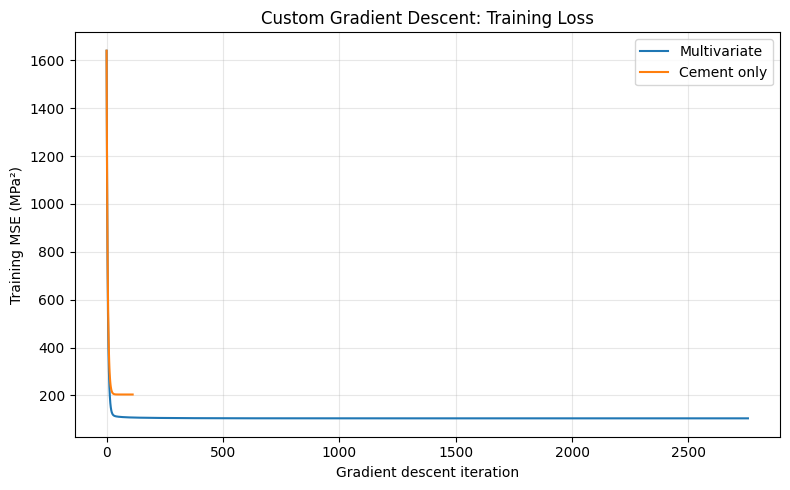

In [7]:
# scale using training data
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0, ddof=0)
train_std = np.where(train_std == 0, 1.0, train_std)

X_train_scaled = (X_train - train_mean) / train_std
X_test_scaled = (X_test - train_mean) / train_std

# all eight predictors
multi_model = gradient_descent(
    X_train_scaled,
    y_train,
    learning_rate=0.05,
    max_iterations=20000,
    tolerance=1e-10
)

# cement only
uni_model = gradient_descent(
    X_train_scaled[:, 0],
    y_train,
    learning_rate=0.05,
    max_iterations=20000,
    tolerance=1e-10
)

results = []

for name, model, train_X, test_X in [
    (
        "Multivariate (standardized)",
        multi_model,
        X_train_scaled,
        X_test_scaled
    ),
    (
        "Cement only (standardized)",
        uni_model,
        X_train_scaled[:, 0],
        X_test_scaled[:, 0]
    )
]:
    train_metrics = evaluate(y_train, predict(train_X, model))
    test_metrics = evaluate(y_test, predict(test_X, model))

    results.append({
        "Model": name,
        "Iterations": model["iterations"],
        "Converged": model["converged"],
        "Training MSE": train_metrics["MSE"],
        "Testing MSE": test_metrics["MSE"],
        "Training R2": train_metrics["R2"],
        "Testing R2": test_metrics["R2"]
    })

print(pd.DataFrame(results).round(4).to_string(index=False))

# convert back to original units
original_coefficients = multi_model["theta"][1:] / train_std
original_intercept = (
    multi_model["theta"][0]
    - np.sum(original_coefficients * train_mean)
)

print("\nIntercept:", original_intercept)
print("\nCoefficients:")
print(pd.Series(original_coefficients, index=feature_names).round(6))

plt.figure(figsize=(8, 5))
plt.plot(multi_model["loss_history"], label="Multivariate")
plt.plot(uni_model["loss_history"], label="Cement only")

plt.xlabel("Gradient descent iteration")
plt.ylabel("Training MSE (MPa²)")
plt.title("Custom Gradient Descent: Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

        Model  Learning rate  Iterations  Converged  Training MSE  Training R2  First positive R2
Untransformed   2.000000e-07       20000      False    104.519930     0.622698                  7
 Standardized   5.000000e-02        2756       True    104.136464     0.624082                 11


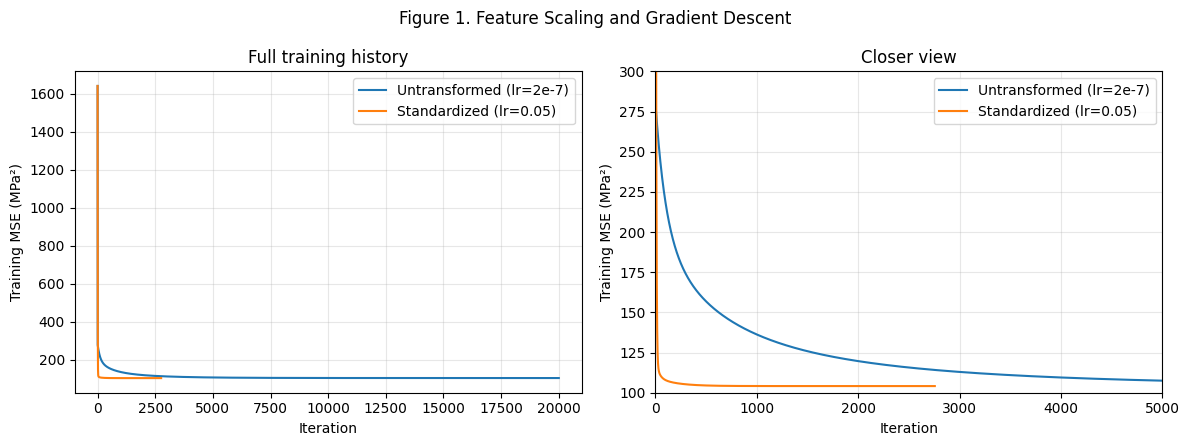

In [8]:
# original features
raw_model = gradient_descent(
    X_train,
    y_train,
    learning_rate=2e-7,
    max_iterations=20000,
    tolerance=1e-10
)

# standardized features
scaled_model = gradient_descent(
    X_train_scaled,
    y_train,
    learning_rate=0.05,
    max_iterations=20000,
    tolerance=1e-10
)

rows = []

for name, model, X in [
    ("Untransformed", raw_model, X_train),
    ("Standardized", scaled_model, X_train_scaled)
]:
    metrics = evaluate(y_train, predict(X, model))

    # first iteration with positive training r2
    positive = np.flatnonzero(
        model["loss_history"] < np.var(y_train, ddof=0)
    )

    rows.append({
        "Model": name,
        "Learning rate": model["learning_rate"],
        "Iterations": model["iterations"],
        "Converged": model["converged"],
        "Training MSE": metrics["MSE"],
        "Training R2": metrics["R2"],
        "First positive R2": int(positive[0]) if len(positive) else None
    })

    assert metrics["R2"] > 0

print(pd.DataFrame(rows).to_string(index=False))

# full curve and closer view
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax in axes:
    ax.plot(
        raw_model["loss_history"],
        label="Untransformed (lr=2e-7)"
    )
    ax.plot(
        scaled_model["loss_history"],
        label="Standardized (lr=0.05)"
    )
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Training MSE (MPa²)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_title("Full training history")
axes[1].set_title("Closer view")
axes[1].set_xlim(0, 5000)
axes[1].set_ylim(100, 300)

fig.suptitle("Figure 1. Feature Scaling and Gradient Descent")
plt.tight_layout()
plt.savefig("q3_scaling_loss.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
from google.colab import files
files.download("q3_scaling_loss.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
from sklearn.linear_model import LinearRegression

# fit both models
raw_optimal = LinearRegression().fit(X_train, y_train)
scaled_optimal = LinearRegression().fit(X_train_scaled, y_train)

comparison = []

for name, model, train_X, test_X in [
    ("Untransformed", raw_optimal, X_train, X_test),
    ("Standardized", scaled_optimal, X_train_scaled, X_test_scaled)
]:
    train_metrics = evaluate(y_train, model.predict(train_X))
    test_metrics = evaluate(y_test, model.predict(test_X))

    comparison.append({
        "Model": name,
        "Training MSE": train_metrics["MSE"],
        "Testing MSE": test_metrics["MSE"],
        "Training R2": train_metrics["R2"],
        "Testing R2": test_metrics["R2"]
    })

print(pd.DataFrame(comparison).round(6).to_string(index=False))

# compare predictions
difference = np.max(np.abs(
    raw_optimal.predict(X_test)
    - scaled_optimal.predict(X_test_scaled)
))

print("\nLargest prediction difference:", difference)

# compare coefficients in the same units
coef_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Original coefficient": raw_optimal.coef_,
    "Scaled coefficient converted back": scaled_optimal.coef_ / train_std
})

print("\n", coef_comparison.round(6).to_string(index=False))

        Model  Training MSE  Testing MSE  Training R2  Testing R2
Untransformed    104.136462   141.235622     0.624082     0.36881
 Standardized    104.136462   141.235622     0.624082     0.36881

Largest prediction difference: 5.684341886080802e-14

          Feature  Original coefficient  Scaled coefficient converted back
          Cement              0.132458                           0.132458
            Slag              0.124742                           0.124742
          FlyAsh              0.106131                           0.106131
           Water             -0.133716                          -0.133716
Superplasticizer              0.118918                           0.118918
 CoarseAggregate              0.028609                           0.028609
   FineAggregate              0.033870                           0.033870
             Age              0.118804                           0.118804


Iterations: 20000
Converged: False
Training: {'MSE': 56.93736044234442, 'R2': 0.7944640269752}
Testing: {'MSE': 51.258630552611066, 'R2': 0.7709223453198906}


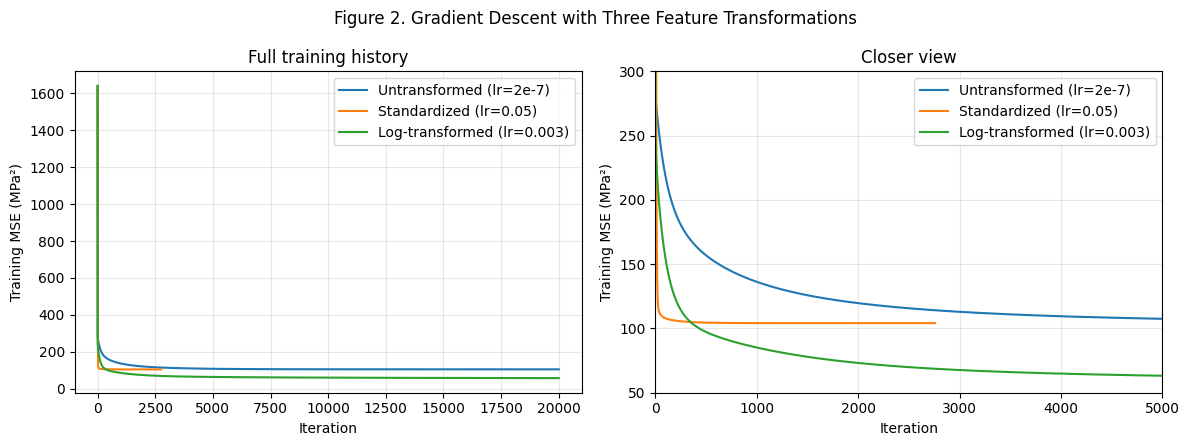

In [11]:
# log transform
X_train_log = np.log1p(X_train)
X_test_log = np.log1p(X_test)

log_model = gradient_descent(
    X_train_log,
    y_train,
    learning_rate=0.003,
    max_iterations=20000,
    tolerance=1e-10
)

print("Iterations:", log_model["iterations"])
print("Converged:", log_model["converged"])
print("Training:", evaluate(
    y_train, predict(X_train_log, log_model)
))
print("Testing:", evaluate(
    y_test, predict(X_test_log, log_model)
))

# compare all three
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax in axes:
    for label, model in [
        ("Untransformed (lr=2e-7)", raw_model),
        ("Standardized (lr=0.05)", scaled_model),
        ("Log-transformed (lr=0.003)", log_model)
    ]:
        ax.plot(model["loss_history"], label=label)

    ax.set_xlabel("Iteration")
    ax.set_ylabel("Training MSE (MPa²)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_title("Full training history")
axes[1].set_title("Closer view")
axes[1].set_xlim(0, 5000)
axes[1].set_ylim(50, 300)

fig.suptitle("Figure 2. Gradient Descent with Three Feature Transformations")
plt.tight_layout()
plt.savefig("q5_log_loss.png", dpi=300, bbox_inches="tight")
plt.show()

          Model  Training MSE  Testing MSE  Training R2  Testing R2
  Untransformed      104.1365     141.2356       0.6241      0.3688
   Standardized      104.1365     141.2356       0.6241      0.3688
Log-transformed       55.8300      54.3614       0.7985      0.7571


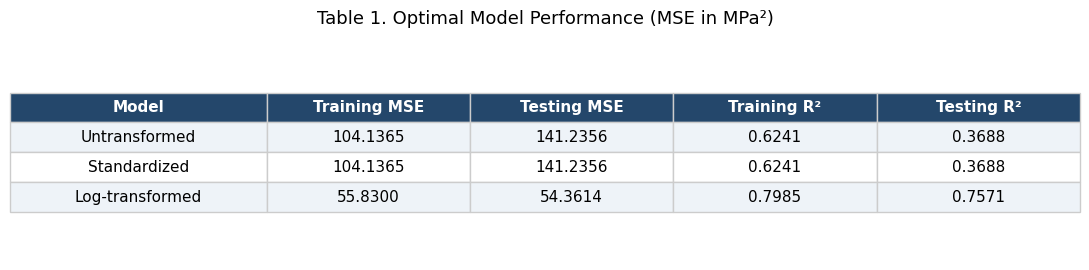

In [12]:
# optimal log model
log_optimal = LinearRegression().fit(X_train_log, y_train)

summary_rows = []

for name, model, train_X, test_X in [
    ("Untransformed", raw_optimal, X_train, X_test),
    ("Standardized", scaled_optimal, X_train_scaled, X_test_scaled),
    ("Log-transformed", log_optimal, X_train_log, X_test_log)
]:
    train_metrics = evaluate(y_train, model.predict(train_X))
    test_metrics = evaluate(y_test, model.predict(test_X))

    summary_rows.append({
        "Model": name,
        "Training MSE": train_metrics["MSE"],
        "Testing MSE": test_metrics["MSE"],
        "Training R2": train_metrics["R2"],
        "Testing R2": test_metrics["R2"]
    })

optimal_summary = pd.DataFrame(summary_rows)
print(optimal_summary.round(4).to_string(index=False))

# save table as an image
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.axis("off")

table = ax.table(
    cellText=[
        [row[0]] + [f"{value:.4f}" for value in row[1:]]
        for row in optimal_summary.itertuples(index=False, name=None)
    ],
    colLabels=[
        "Model", "Training MSE", "Testing MSE",
        "Training R²", "Testing R²"
    ],
    cellLoc="center",
    loc="center",
    colWidths=[0.24, 0.19, 0.19, 0.19, 0.19]
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.8)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("#cccccc")
    if r == 0:
        cell.set_facecolor("#24476b")
        cell.set_text_props(color="white", weight="bold")
    elif r % 2 == 1:
        cell.set_facecolor("#eef3f8")

ax.set_title(
    "Table 1. Optimal Model Performance (MSE in MPa²)",
    fontsize=13,
    pad=15
)

plt.tight_layout()
plt.savefig("q5_optimal_table.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
from google.colab import files

files.download("q5_log_loss.png")
files.download("q5_optimal_table.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
uni_models = {}
uni_results = []

for i, feature in enumerate(feature_names):
    x = X_train[:, i]

    # choose a stable step from training data
    A = design_matrix(x)
    largest_eigenvalue = np.linalg.eigvalsh(
        A.T @ A / len(y_train)
    )[-1]
    lr = 0.9 / largest_eigenvalue

    model = gradient_descent(
        x,
        y_train,
        learning_rate=lr,
        max_iterations=20000,
        tolerance=1e-10
    )

    uni_models[feature] = model
    train_metrics = evaluate(y_train, predict(x, model))
    test_metrics = evaluate(
        y_test, predict(X_test[:, i], model)
    )

    positive = np.flatnonzero(
        model["loss_history"] < np.var(y_train, ddof=0)
    )

    uni_results.append({
        "Feature": feature,
        "Learning rate": lr,
        "Iterations": model["iterations"],
        "Training R2": train_metrics["R2"],
        "Testing R2": test_metrics["R2"],
        "First positive R2": int(positive[0]) if len(positive) else None
    })

uni_results = pd.DataFrame(uni_results)
print(uni_results.to_string(index=False))

positive_count = (uni_results["Training R2"] > 0).sum()
print("\nModels with positive training R2:", positive_count)
assert positive_count >= 2

         Feature  Learning rate  Iterations  Training R2  Testing R2  First positive R2
          Cement   1.017689e-05       20000     0.177794   -0.142295                8.0
            Slag   7.001763e-05       20000    -0.083479   -0.395402                NaN
          FlyAsh   1.213326e-04       20000     0.027939   -0.436951            16026.0
           Water   2.714471e-05       20000    -0.212053   -0.478593                NaN
Superplasticizer   1.078655e-02        1052     0.101782    0.116383              144.0
 CoarseAggregate   9.431801e-07       20000    -0.075634   -0.538428                NaN
   FineAggregate   1.492058e-06       20000    -0.124193   -0.488782                NaN
             Age   1.531589e-04       20000     0.121927   -0.318990             7635.0

Models with positive training R2: 4


         Feature  Univariate coefficient  Multivariate coefficient
          Cement                0.080785                  0.132458
            Slag                0.031599                  0.124742
          FlyAsh               -0.053404                  0.106131
           Water               -0.207049                 -0.133716
Superplasticizer                0.888122                  0.118918
 CoarseAggregate               -0.027384                  0.028609
   FineAggregate               -0.030580                  0.033870
             Age                0.095208                  0.118804


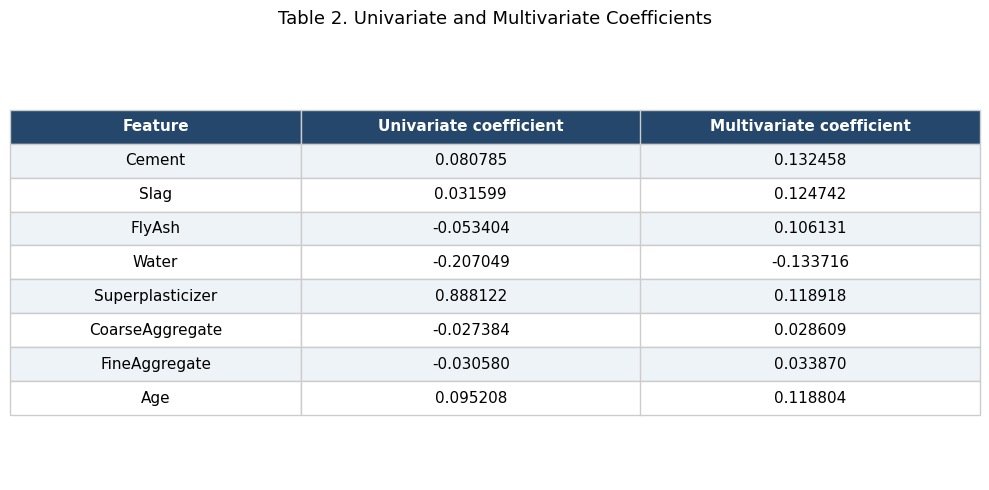

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
coef_rows = []

for i, feature in enumerate(feature_names):
    model = LinearRegression().fit(
        X_train[:, i:i+1], y_train
    )

    coef_rows.append({
        "Feature": feature,
        "Univariate coefficient": model.coef_[0],
        "Multivariate coefficient": raw_optimal.coef_[i]
    })

uni_coef_table = pd.DataFrame(coef_rows)
print(uni_coef_table.round(6).to_string(index=False))

# save coefficient table
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis("off")

table = ax.table(
    cellText=[
        [row[0], f"{row[1]:.6f}", f"{row[2]:.6f}"]
        for row in uni_coef_table.itertuples(index=False, name=None)
    ],
    colLabels=[
        "Feature", "Univariate coefficient",
        "Multivariate coefficient"
    ],
    cellLoc="center",
    loc="center",
    colWidths=[0.30, 0.35, 0.35]
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.8)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("#cccccc")
    if r == 0:
        cell.set_facecolor("#24476b")
        cell.set_text_props(color="white", weight="bold")
    elif r % 2 == 1:
        cell.set_facecolor("#eef3f8")

ax.set_title(
    "Table 2. Univariate and Multivariate Coefficients",
    fontsize=13,
    pad=15
)

plt.tight_layout()
plt.savefig("q6_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("q6_coefficients.png")

,Feature,Untransformed,Standardized,Log-transformed
0,Cement,2.461200e-40,2.461200e-40,1.100482e-85
1,Slag,6.354749e-26,6.354749e-26,7.344729e-36
2,FlyAsh,3.318101e-13,3.318101e-13,2.948676e-01
3,Water,1.842734e-03,1.842734e-03,1.680104e-20
4,Superplasticizer,2.362551e-01,2.362551e-01,8.082551e-06
5,CoarseAggregate,5.474659e-03,5.474659e-03,4.054171e-01
6,FineAggregate,2.941631e-03,2.941631e-03,8.874613e-02
7,Age,8.526523e-74,8.526523e-74,1.737369e-192


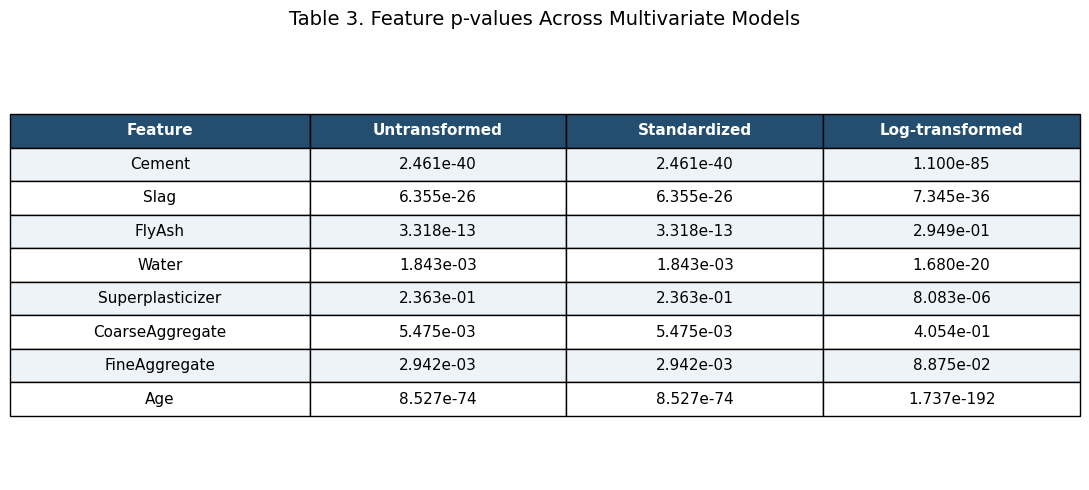

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import statsmodels.api as sm

# fit the three models
ols_raw = sm.OLS(y_train, sm.add_constant(X_train)).fit()
ols_scaled = sm.OLS(y_train, sm.add_constant(X_train_scaled)).fit()
ols_log = sm.OLS(y_train, sm.add_constant(X_train_log)).fit()

pvalue_table = pd.DataFrame({
    "Feature": feature_names,
    "Untransformed": np.asarray(ols_raw.pvalues)[1:],
    "Standardized": np.asarray(ols_scaled.pvalues)[1:],
    "Log-transformed": np.asarray(ols_log.pvalues)[1:]
})

display(pvalue_table)

# make the table
table_rows = [
    [row["Feature"]] + [
        f"{row[col]:.3e}"
        for col in ["Untransformed", "Standardized", "Log-transformed"]
    ]
    for _, row in pvalue_table.iterrows()
]

fig, ax = plt.subplots(figsize=(11, 5))
ax.axis("off")

table = ax.table(
    cellText=table_rows,
    colLabels=pvalue_table.columns,
    cellLoc="center",
    loc="center",
    colWidths=[0.28, 0.24, 0.24, 0.24]
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.8)

for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor("#234e70")
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor("#eef3f8" if r % 2 else "white")

ax.set_title(
    "Table 3. Feature p-values Across Multivariate Models",
    fontsize=14,
    pad=18
)
plt.tight_layout()
plt.savefig("q7_pvalues.png", dpi=200, bbox_inches="tight")
plt.show()

from google.colab import files
files.download("q7_pvalues.png")

Part2

,Mean,SD,Minimum,Maximum
Cement,277.87,106.00,102.00,540.0
Slag,76.11,84.08,0.00,305.3
FlyAsh,57.38,64.26,0.00,200.1
Water,180.72,22.28,121.80,247.0
Superplasticizer,6.86,5.98,0.00,32.2
CoarseAggregate,973.76,77.57,801.00,1145.0
FineAggregate,772.33,81.91,594.00,992.6
Age,46.04,61.32,1.00,365.0
Strength,36.93,16.65,2.33,82.6


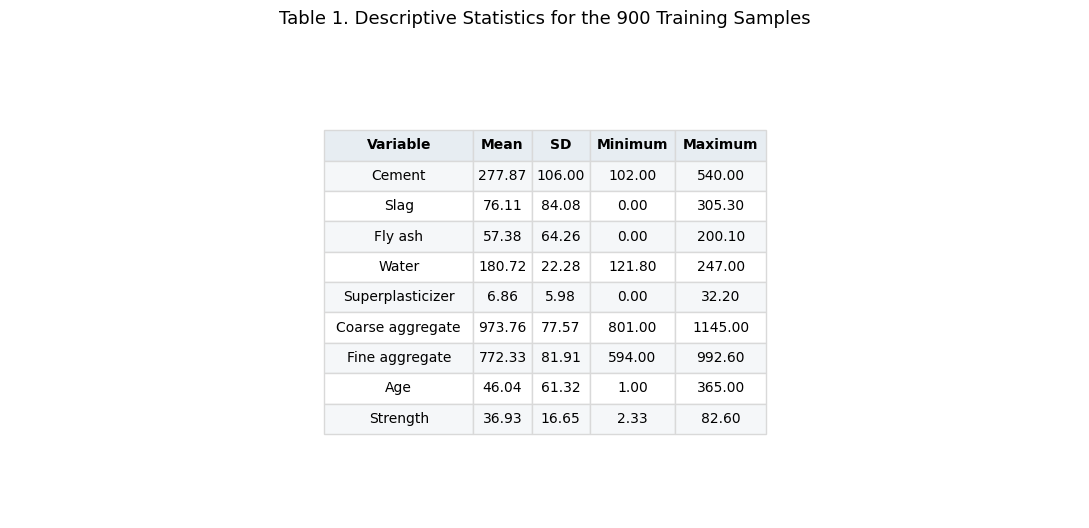

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# training data only
columns = [
    "Cement", "Slag", "FlyAsh", "Water",
    "Superplasticizer", "CoarseAggregate",
    "FineAggregate", "Age", "Strength"
]

assert len(train_df) == 900
assert len(test_df) == 130

summary = train_df[columns].agg(
    ["mean", "std", "min", "max"]
).T

summary.columns = ["Mean", "SD", "Minimum", "Maximum"]

display(summary.round(2))

# save a table image
def save_report_table(data, filename, title, first_column):
    rows = [
        [str(index)] + [
            f"{value:.2f}" if isinstance(value, (float, np.floating))
            else str(value)
            for value in row
        ]
        for index, row in data.iterrows()
    ]

    fig, ax = plt.subplots(figsize=(11, 0.42 * len(data) + 1.6))
    ax.axis("off")

    table = ax.table(
        cellText=rows,
        colLabels=[first_column] + list(data.columns),
        cellLoc="center",
        loc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.6)
    table.auto_set_column_width(range(len(data.columns) + 1))

    for (r, c), cell in table.get_celld().items():
        cell.set_edgecolor("#d9d9d9")
        if r == 0:
            cell.set_facecolor("#e7edf2")
            cell.set_text_props(weight="bold")
        else:
            cell.set_facecolor("#f5f7f9" if r % 2 else "white")

    ax.set_title(title, fontsize=13, pad=16)
    plt.tight_layout()
    plt.savefig(filename, dpi=220, bbox_inches="tight")
    plt.show()

summary_display = summary.rename(index={
    "FlyAsh": "Fly ash",
    "CoarseAggregate": "Coarse aggregate",
    "FineAggregate": "Fine aggregate"
})

save_report_table(
    summary_display,
    "part2_table1_summary.png",
    "Table 1. Descriptive Statistics for the 900 Training Samples",
    "Variable"
)

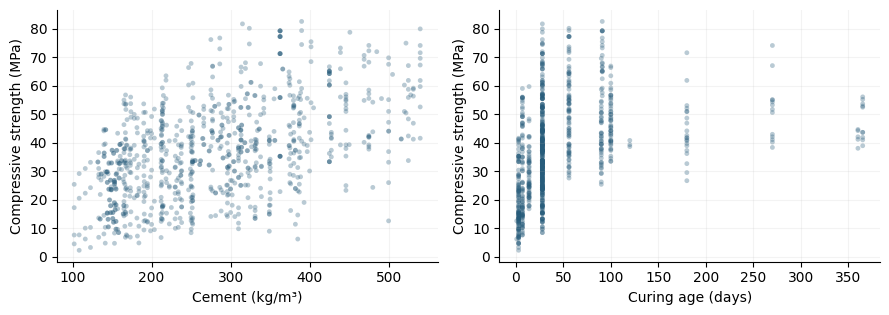

In [18]:
# plot the training samples
plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

fig, axes = plt.subplots(1, 2, figsize=(9, 3.25))

features = ["Cement", "Age"]
labels = ["Cement (kg/m³)", "Curing age (days)"]

for ax, feature, label in zip(axes, features, labels):
    ax.scatter(
        train_df[feature],
        train_df["Strength"],
        s=12,
        alpha=0.32,
        color="#275c7b",
        edgecolors="none"
    )

    ax.set_xlabel(label)
    ax.set_ylabel("Compressive strength (MPa)")
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.savefig(
    "part2_figure1_relationships.png",
    dpi=220,
    bbox_inches="tight"
)
plt.show()

,Training R²,Testing R²,Testing MSE
Model,,,
Original features,0.6241,0.3688,141.2356
Standardized features,0.6241,0.3688,141.2356
Log transformed features,0.7985,0.7571,54.3614


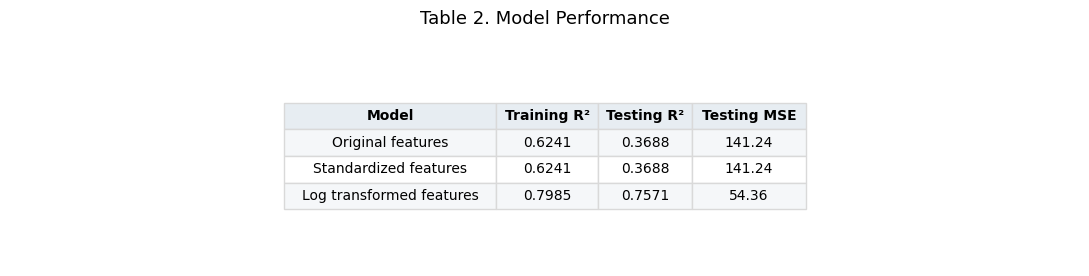

In [19]:
# prepare the inputs
features = columns[:-1]

x_train = train_df[features]
x_test = test_df[features]
target_train = train_df["Strength"]
target_test = test_df["Strength"]

means = x_train.mean()
stds = x_train.std(ddof=0).replace(0, 1)

inputs = {
    "Original features": (
        x_train,
        x_test
    ),
    "Standardized features": (
        (x_train - means) / stds,
        (x_test - means) / stds
    ),
    "Log transformed features": (
        np.log1p(x_train),
        np.log1p(x_test)
    )
}

# fit and evaluate
performance_rows = []

for name, (train_inputs, test_inputs) in inputs.items():
    model = LinearRegression()
    model.fit(train_inputs, target_train)

    train_predictions = model.predict(train_inputs)
    test_predictions = model.predict(test_inputs)

    performance_rows.append({
        "Model": name,
        "Training R²": r2_score(target_train, train_predictions),
        "Testing R²": r2_score(target_test, test_predictions),
        "Testing MSE": mean_squared_error(
            target_test, test_predictions
        )
    })

performance = pd.DataFrame(performance_rows).set_index("Model")

display(performance.round(4))

# format the report table
performance_display = pd.DataFrame(index=performance.index)
performance_display["Training R²"] = performance["Training R²"].map(
    lambda x: f"{x:.4f}"
)
performance_display["Testing R²"] = performance["Testing R²"].map(
    lambda x: f"{x:.4f}"
)
performance_display["Testing MSE"] = performance["Testing MSE"].map(
    lambda x: f"{x:.2f}"
)

save_report_table(
    performance_display,
    "part2_table2_performance.png",
    "Table 2. Model Performance",
    "Model"
)